<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/black-scholes-sp500/sp500_black_scholes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Black-Scholes applied to the S&P 500

In this project I code the Black-Scholes model to price European options on the S&P 500. Then I check whether its assumptions hold on real data (daily closes since 1 January 2000), and I compare the prices with other methods: Monte Carlo, a binomial tree, and a Monte Carlo based on historical returns.

The pricing functions are in `pricing.py`.

In [ ]:
# in Colab, download the repo first so the code and the data are available
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/black-scholes-sp500
except ImportError:
    pass

6762 days, from 2000-01-03 to 2026-11-19


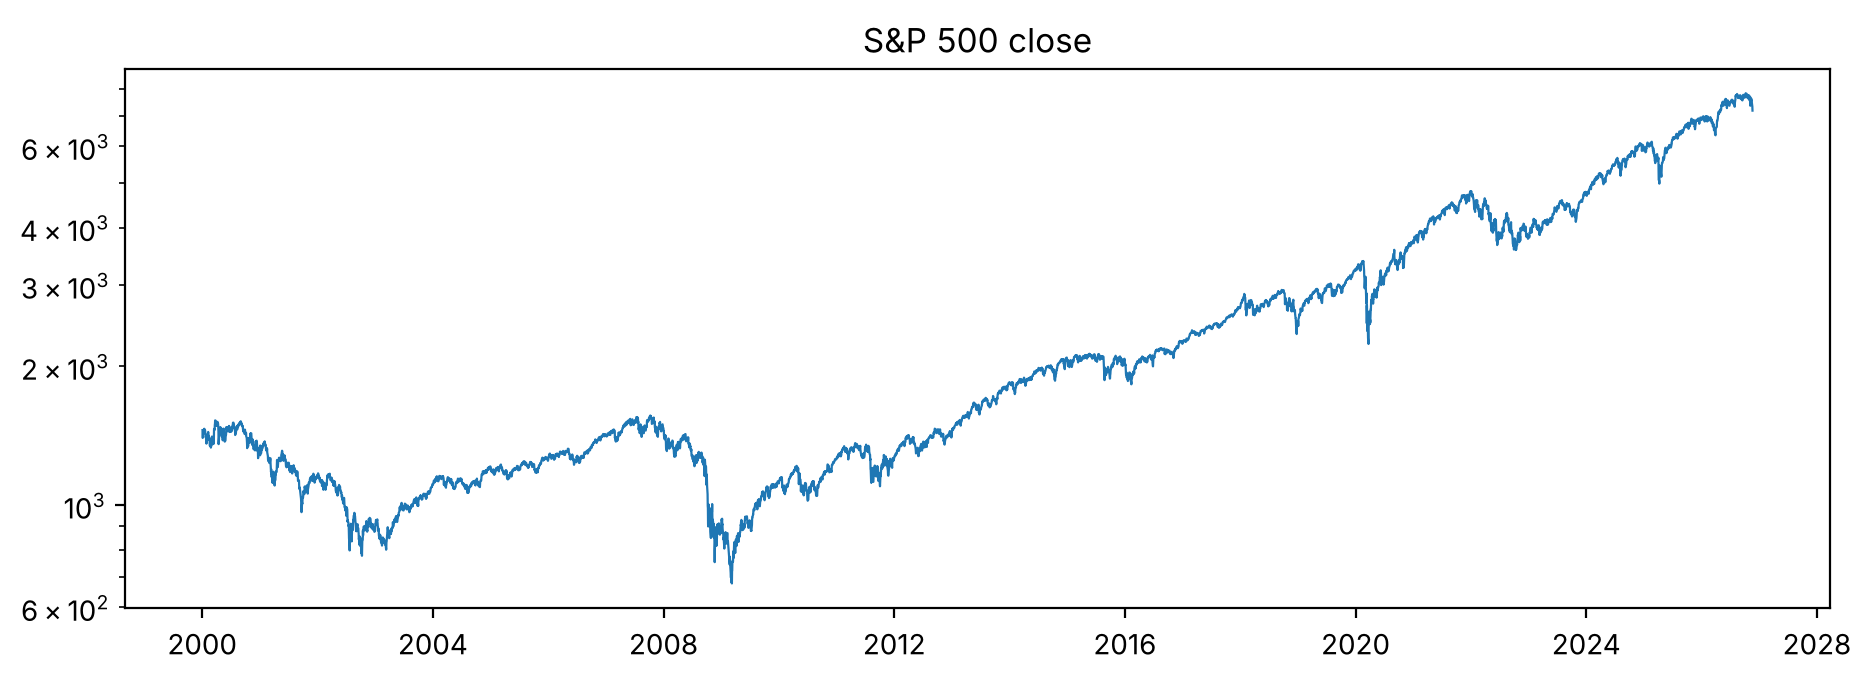

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pricing import black_scholes, monte_carlo, binomial_crr, implied_vol

df = pd.read_csv("data/sp500.csv")
df["Date"] = pd.to_datetime(df["Date"].str[:10])
prices = df.set_index("Date")["Close"].loc["2000-01-01":]
rets = np.log(prices).diff().dropna()   # daily log returns

print(len(prices), "days, from", prices.index[0].date(), "to", prices.index[-1].date())

plt.figure(figsize=(11, 3.5))
plt.plot(prices, lw=0.8)
plt.yscale("log")
plt.title("S&P 500 close")
plt.show()

## 1. The model

Call and put prices:

$$C = S\,N(d_1) - K e^{-rT} N(d_2) \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)$$

with $d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}$ and $d_2 = d_1 - \sigma\sqrt{T}$.

For the inputs I use the last close as spot, the annualised historical volatility since 2000, a 3% rate and a 1-month maturity (21 trading days).

In [2]:
S0 = prices.iloc[-1]
sigma = rets.std() * np.sqrt(252)
r = 0.03
T = 21 / 252

print("spot:", round(S0, 2))
print("historical vol:", round(sigma, 4))
print("1-month ATM call:", round(black_scholes(S0, S0, T, r, sigma), 2))

spot: 7175.83
historical vol: 0.1924
1-month ATM call: 167.92


## 2. Checking the assumptions

Black-Scholes assumes the price follows a geometric Brownian motion. That means two things I can test:
- log returns are normally distributed
- volatility is constant over time

### Are returns normal?

In [3]:
z = (rets - rets.mean()) / rets.std()

print("skewness:", round(stats.skew(rets), 2))
print("excess kurtosis:", round(stats.kurtosis(rets), 2))
print("Jarque-Bera p-value:", stats.jarque_bera(rets).pvalue)
print("Kolmogorov-Smirnov p-value:", stats.kstest(z, "norm").pvalue)

n_extreme = (abs(z) > 4).sum()
expected = len(z) * 2 * stats.norm.sf(4)
print("days beyond 4 std devs:", n_extreme, "/ expected under a normal law:", round(expected, 1))
print("worst day:", round(rets.min(), 3), "on", rets.idxmin().date(), "i.e.", round(z.min(), 1), "std devs")

skewness: -0.35
excess kurtosis: 10.64
Jarque-Bera p-value: 0.0
Kolmogorov-Smirnov p-value: 6.172141174321856e-52
days beyond 4 std devs: 46 / expected under a normal law: 0.4
worst day: -0.128 on 2020-03-16 i.e. -10.6 std devs


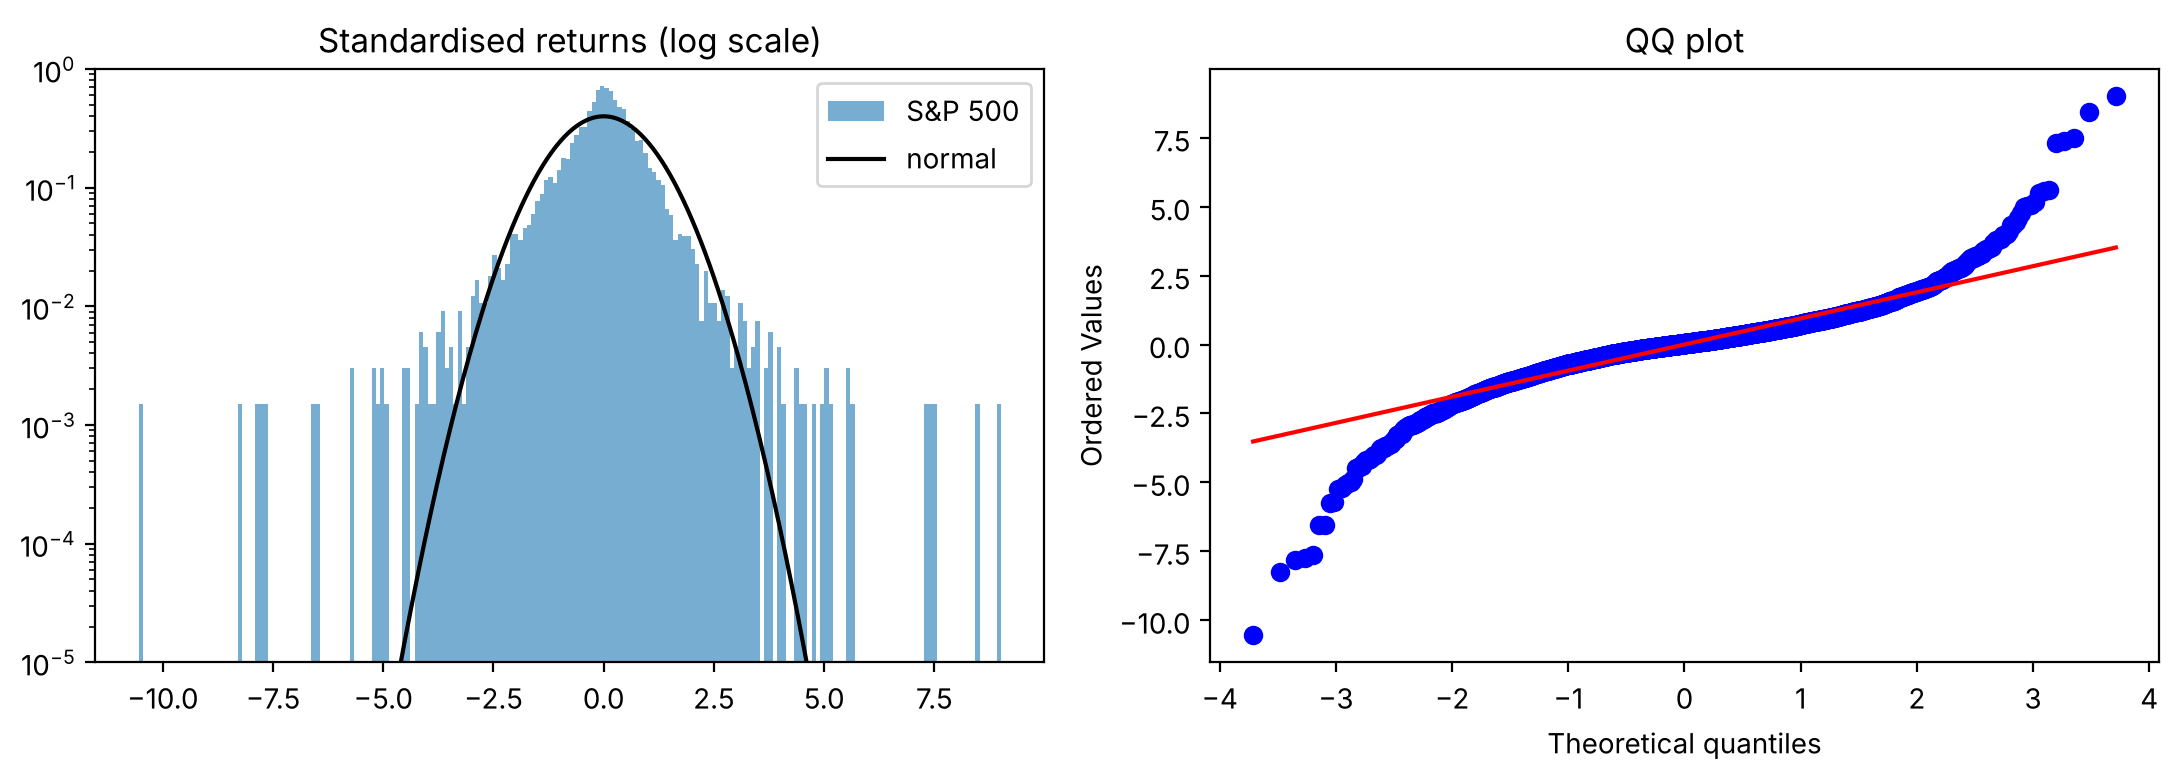

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.linspace(z.min(), z.max(), 400)
ax[0].hist(z, bins=200, density=True, alpha=0.6, label="S&P 500")
ax[0].plot(x, stats.norm.pdf(x), "k", label="normal")
ax[0].set_yscale("log")
ax[0].set_ylim(1e-5, 1)
ax[0].set_title("Standardised returns (log scale)")
ax[0].legend()
stats.probplot(z, dist="norm", plot=ax[1])
ax[1].set_title("QQ plot")
plt.tight_layout()
plt.show()

Both tests reject normality (p-values basically zero). Excess kurtosis is around 10 when it should be 0, so the tails are much fatter than a normal law. There are 46 days beyond 4 standard deviations when we would expect less than 1. The March 2020 crash is more than 10 standard deviations, which is practically impossible under a normal law. Skewness is negative: big drops happen more often than big rises.

### Is volatility constant?

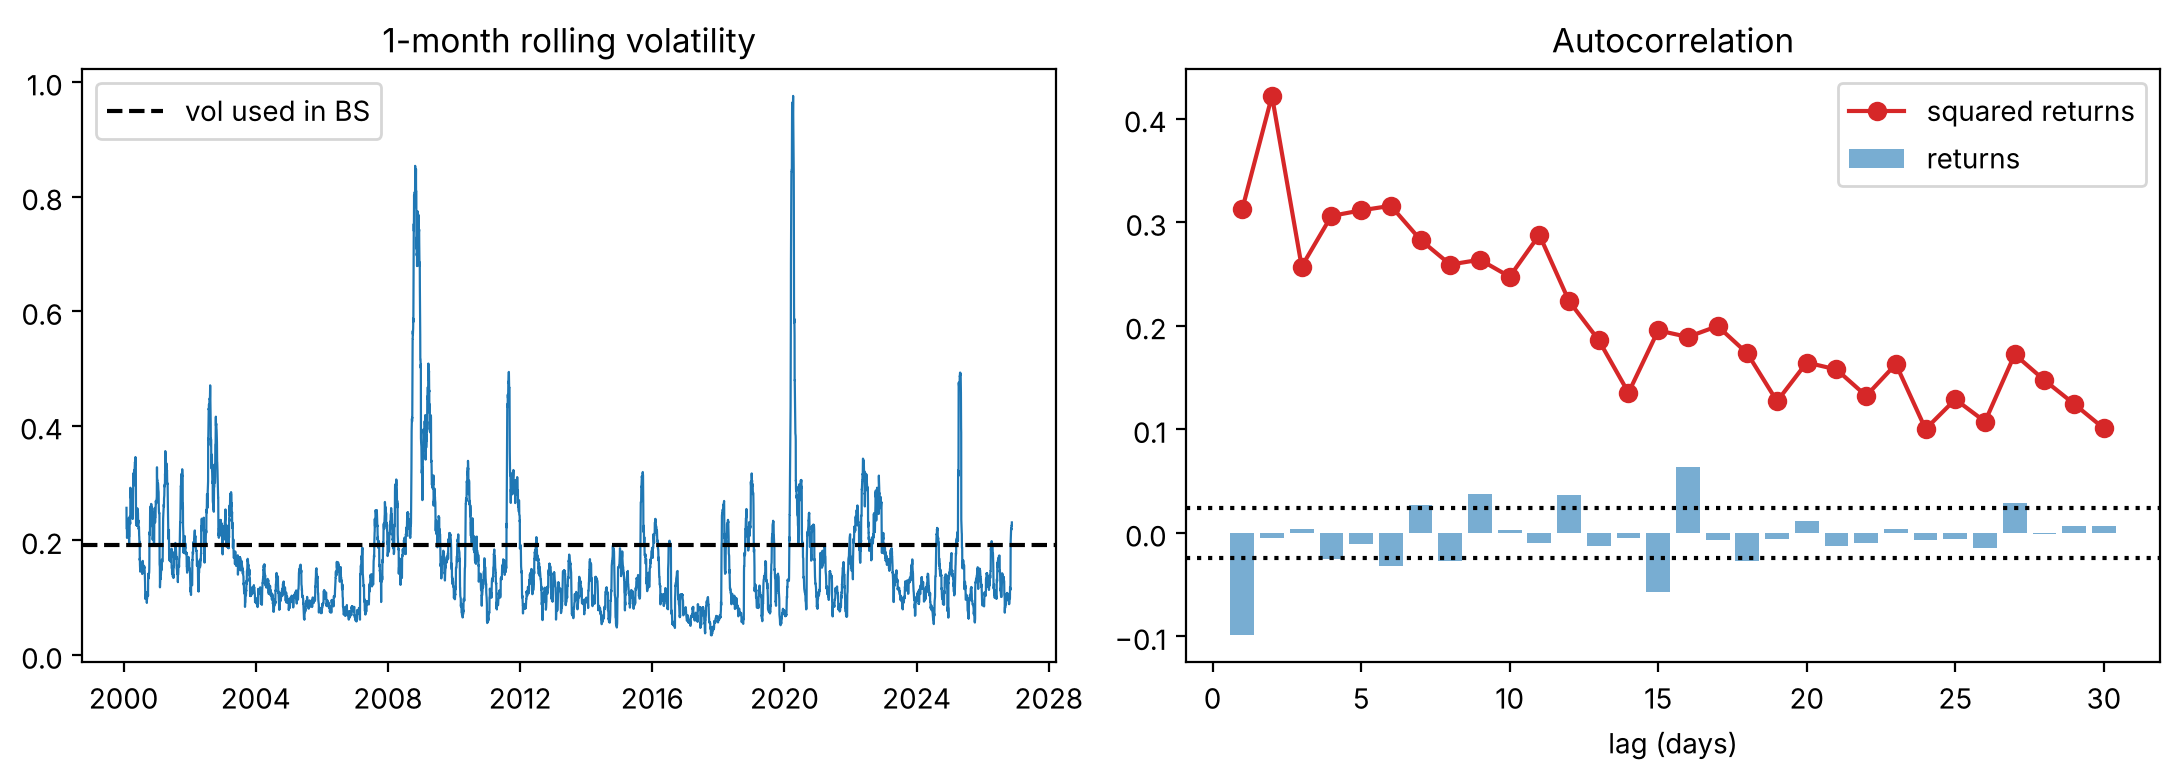

min vol: 0.035 on 2017-10-11
max vol: 0.976 on 2020-04-06


In [5]:
rolling_vol = rets.rolling(21).std() * np.sqrt(252)

def autocorr(x, k):
    return np.corrcoef(x[:-k], x[k:])[0, 1]

lags = range(1, 31)
ac_rets = [autocorr(rets.values, k) for k in lags]
ac_sq = [autocorr(rets.values**2, k) for k in lags]
band = 1.96 / np.sqrt(len(rets))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rolling_vol, lw=0.8)
ax[0].axhline(sigma, color="k", ls="--", label="vol used in BS")
ax[0].set_title("1-month rolling volatility")
ax[0].legend()
ax[1].bar(lags, ac_rets, alpha=0.6, label="returns")
ax[1].plot(lags, ac_sq, "o-", color="C3", label="squared returns")
ax[1].axhline(band, color="k", ls=":")
ax[1].axhline(-band, color="k", ls=":")
ax[1].set_title("Autocorrelation")
ax[1].set_xlabel("lag (days)")
ax[1].legend()
plt.tight_layout()
plt.show()

print("min vol:", round(rolling_vol.min(), 3), "on", rolling_vol.idxmin().date())
print("max vol:", round(rolling_vol.max(), 3), "on", rolling_vol.idxmax().date())

Volatility is clearly not constant: it goes from about 3% in 2017 to almost 100% in April 2020, with spikes in 2008 and 2020. Returns themselves are barely autocorrelated, but squared returns stay correlated for several weeks. In other words, once the market gets nervous it stays nervous for a while (volatility clustering).

So both Black-Scholes assumptions are wrong for the S&P 500.

## 3. Comparison with reference methods

### Monte Carlo and binomial tree

First I check my implementation: with the same assumptions (S&P 500 spot and vol), a Monte Carlo and a 2000-step CRR binomial tree should give the same price as the closed formula.

In [6]:
for m in [0.95, 1.00, 1.05]:
    for kind in ["call", "put"]:
        K = m * S0
        bs = black_scholes(S0, K, T, r, sigma, kind)
        mc, se = monte_carlo(S0, K, T, r, sigma, kind)
        crr = binomial_crr(S0, K, T, r, sigma, kind)
        print(f"K/S0={m}  {kind}  BS={bs:.2f}  MC={mc:.2f} (95% CI: {mc-1.96*se:.2f} - {mc+1.96*se:.2f})  CRR={crr:.2f}")

K/S0=0.95  call  BS=410.12  MC=410.23 (95% CI: 409.55 - 410.91)  CRR=410.13
K/S0=0.95  put  BS=34.31  MC=34.39 (95% CI: 34.19 - 34.59)  CRR=34.32
K/S0=1.0  call  BS=167.92  MC=168.16 (95% CI: 167.67 - 168.64)  CRR=167.90
K/S0=1.0  put  BS=150.00  MC=150.21 (95% CI: 149.78 - 150.64)  CRR=149.98
K/S0=1.05  call  BS=46.21  MC=46.32 (95% CI: 46.06 - 46.58)  CRR=46.22


K/S0=1.05  put  BS=386.19  MC=386.27 (95% CI: 385.63 - 386.91)  CRR=386.20


The three methods agree within a few cents and BS is always inside the Monte Carlo confidence interval, so the code is right. But these two methods rely on the same assumptions as BS, so they say nothing about whether the model fits the market.

### Monte Carlo on historical returns

To get a reference that does not assume normality, I simulate 1-month paths by randomly drawing real S&P 500 daily returns (bootstrap). I centre the returns and adjust the final prices so the discounted expectation equals S0, otherwise the comparison with BS would not be fair.

Then I compute the implied volatility of each price, i.e. the vol you would need to put in BS to get that price.

K/S0=0.85  put  bootstrap=0.58  BS=0.16  ratio=3.74  implied vol=0.219
K/S0=0.88  put  bootstrap=2.27  BS=1.19  ratio=1.90  implied vol=0.210
K/S0=0.9  put  bootstrap=5.28  BS=3.74  ratio=1.41  implied vol=0.204
K/S0=0.93  put  bootstrap=17.11  BS=15.65  ratio=1.09  implied vol=0.197
K/S0=0.95  put  bootstrap=34.72  BS=34.31  ratio=1.01  implied vol=0.193
K/S0=0.97  put  bootstrap=65.47  BS=66.84  ratio=0.98  implied vol=0.190
K/S0=1.0  call  bootstrap=164.26  BS=167.92  ratio=0.98  implied vol=0.188
K/S0=1.03  call  bootstrap=78.05  BS=81.52  ratio=0.96  implied vol=0.188
K/S0=1.05  call  bootstrap=44.14  BS=46.21  ratio=0.96  implied vol=0.189
K/S0=1.08  call  bootstrap=17.23  BS=17.27  ratio=1.00  implied vol=0.192
K/S0=1.1  call  bootstrap=8.83  BS=8.19  ratio=1.08  implied vol=0.195


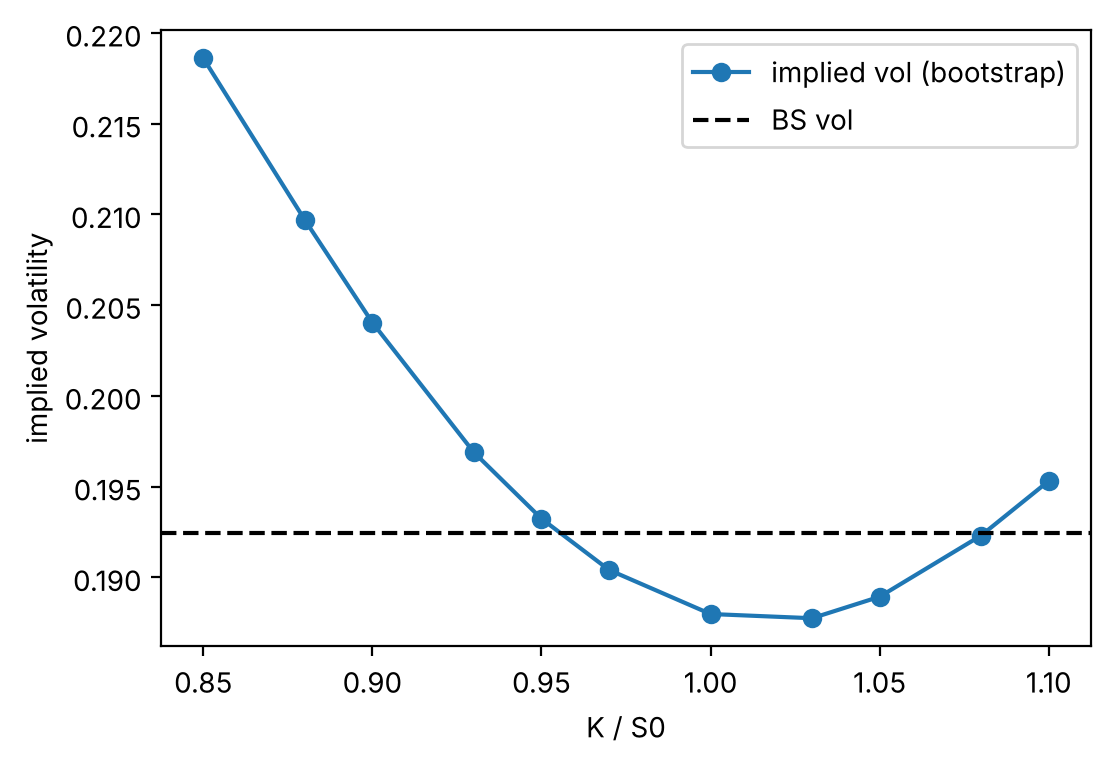

In [7]:
rng = np.random.default_rng(0)
draws = rng.choice(rets.values - rets.mean(), size=(200_000, 21))
ST = S0 * np.exp(draws.sum(axis=1))
ST = ST * S0 * np.exp(r * T) / ST.mean()   # martingale correction

strikes = [0.85, 0.88, 0.90, 0.93, 0.95, 0.97, 1.00, 1.03, 1.05, 1.08, 1.10]
implied = []
for m in strikes:
    K = m * S0
    kind = "put" if m < 1 else "call"
    if kind == "put":
        payoff = np.maximum(K - ST, 0)
    else:
        payoff = np.maximum(ST - K, 0)
    p_boot = np.exp(-r * T) * payoff.mean()
    p_bs = black_scholes(S0, K, T, r, sigma, kind)
    iv = implied_vol(p_boot, S0, K, T, r, kind)
    implied.append(iv)
    print(f"K/S0={m}  {kind}  bootstrap={p_boot:.2f}  BS={p_bs:.2f}  ratio={p_boot/p_bs:.2f}  implied vol={iv:.3f}")

plt.figure(figsize=(6, 4))
plt.plot(strikes, implied, "o-", label="implied vol (bootstrap)")
plt.axhline(sigma, color="k", ls="--", label="BS vol")
plt.xlabel("K / S0")
plt.ylabel("implied volatility")
plt.legend()
plt.show()

With BS the vol is the same for every strike (flat line). With real returns, implied vol goes up for low strikes. The put at 85% of spot is worth about 3.7 times the BS price because of the fat left tail. This is the volatility skew you see on index options.

Limitation: drawing days independently loses the volatility clustering, so over a month the tails get smoothed a bit. The real market skew is steeper.

## 4. Conclusion

- The BS implementation is correct (same price as Monte Carlo and the binomial tree).
- On the S&P 500 since 2000, returns are not normal (fat tails, negative skew) and volatility is not constant.
- As a result, BS with a single historical vol underprices out-of-the-money puts.

To go further, a GARCH model could capture the changing volatility, and a Heston or jump model could be used for pricing.